# APRENDIZAJE AUTOMÁTICO Y ANÁLISIS VISUAL DE DATOS
Jaime Rodrigo Roldán Corcelles

## Ejercicio práctico: Evaluación de modelos y métricas de rendimiento avanzadas

### EJERCICIOS BÁSICOS
1) (1.5 ptos) Considere el conjunto de muestras ionosphere.csv disponible en el Campus Virtual y realice las siguientes tareas:<br>

a) Preprocese el conjunto de muestras y estandarice las muestras.

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import learning_curve, validation_curve
from sklearn.pipeline import make_pipeline


# Cargar el dataset 
df_iono = pd.read_csv('data/ionosphere.csv', header=None)

X = df_iono.iloc[:, :-1].values
y = df_iono.iloc[:, -1].values

# Codificar la clase deseada a valores numéricos (0 y 1)
mapeador_clase = LabelEncoder()
y = mapeador_clase.fit_transform(y)

# Crear un pipeline que primero estandarice los datos y luego aplique el modelo.
pipe_rl = make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter=200, solver='lbfgs', random_state=1))

b) Analice el rendimiento de un modelo basado en regresión logística con 200 épocas de entrenamiento y método “lbfgs”. Dibuje las curvas de exactitud en entrenamiento y en test en función del porcentaje de muestras de entrenamiento y las desviaciones típicas. Para ello, considere conjuntos de entrenamiento del 10, 20, 30, 40, 50, 60, 70, 80 y 90 por ciento del conjunto de muestras y utilice 12 pliegues en el método learning_curve.
¿Cuál configuración cree que es la mejor?. ¿Existe alguna configuración en la que se produzca sobreajuste? ¿en cuál? ¿y subajuste? Razone todas sus respuestas.

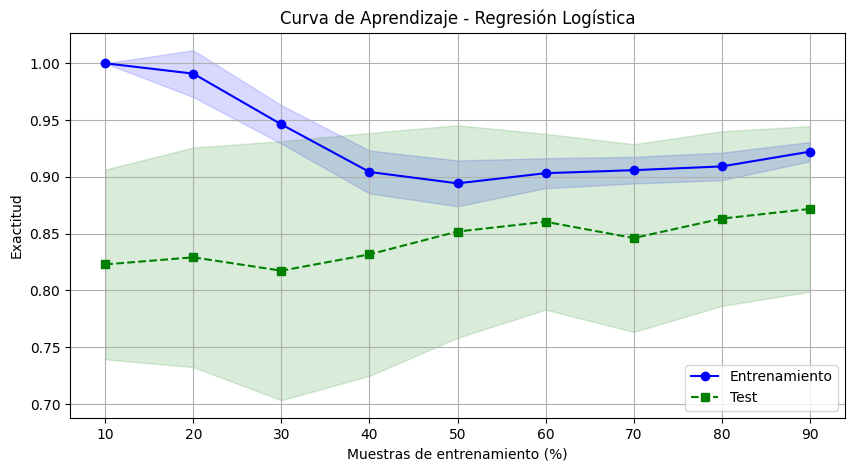

In [52]:
# Porcentajes del 10% al 90%
train_sizes_porcentajes = np.linspace(0.1, 0.9, 9)

tamaños_ent, rend_ent, rend_test = learning_curve(
    estimator=pipe_rl, X=X, y=y,
    train_sizes=train_sizes_porcentajes, cv=12, n_jobs=-1
)

media_ent_lc, desv_ent_lc = np.mean(rend_ent, axis=1), np.std(rend_ent, axis=1)
media_test_lc, desv_test_lc = np.mean(rend_test, axis=1), np.std(rend_test, axis=1)

plt.figure(figsize=(10, 5))
plt.plot(train_sizes_porcentajes * 100, media_ent_lc, color='blue', marker='o', label='Entrenamiento')
plt.fill_between(train_sizes_porcentajes * 100, media_ent_lc + desv_ent_lc, media_ent_lc - desv_ent_lc, alpha=0.15, color='blue')

plt.plot(train_sizes_porcentajes * 100, media_test_lc, color='green', linestyle='--', marker='s', label='Test')
plt.fill_between(train_sizes_porcentajes * 100, media_test_lc + desv_test_lc, media_test_lc - desv_test_lc, alpha=0.15, color='green')

plt.title('Curva de Aprendizaje - Regresión Logística')
plt.xlabel('Muestras de entrenamiento (%)')
plt.ylabel('Exactitud')
plt.legend(loc='lower right')
plt.grid()
plt.show()

* Mejor configuración: Usando el 80%-90% de los datos. La curva de test alcanza su máximo y converge con la de entrenamiento, logrando buena generalización.
* Sobreajuste: Se da entre el 10% y 30%. El modelo memoriza (entrenamiento $\approx$ 1.0) pero falla en datos nuevos (test bajo, gran brecha entre curvas).
* Subajuste: No se observa. Las curvas no convergen a la baja en ningún momento.

c) Analice el rendimiento de un modelo basado en regresión logística con 200 épocas de entrenamiento y método “lbfgs”. Dibuje las curvas de exactitud en entrenamiento y test en función de C y las desviaciones típicas. Emplee 16 valores equiespaciados del parámetro de regularización en el intervalo 𝐶=[10−5,1] usando escala logarítmica. Utilice 10 pliegues en el método validation_curve.
¿Cuál configuración cree que es la mejor?. ¿Existe alguna configuración en la que se produzca sobreajuste? ¿en cuál? ¿y subajuste? Razone todas sus respuestas.

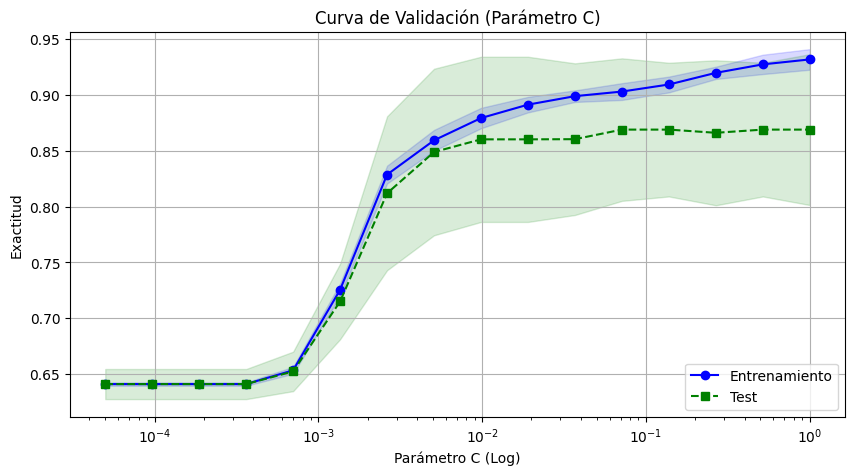

In [53]:
# 16 valores en escala logarítmica [5e-5, 1]
rango_c = np.logspace(np.log10(5e-5), np.log10(1), 16)

rend_ent_vc, rend_test_vc = validation_curve(
    estimator=pipe_rl, X=X, y=y,
    param_name='logisticregression__C',
    param_range=rango_c, cv=10, n_jobs=-1
)

media_ent_vc, desv_ent_vc = np.mean(rend_ent_vc, axis=1), np.std(rend_ent_vc, axis=1)
media_test_vc, desv_test_vc = np.mean(rend_test_vc, axis=1), np.std(rend_test_vc, axis=1)

plt.figure(figsize=(10, 5))
plt.plot(rango_c, media_ent_vc, color='blue', marker='o', label='Entrenamiento')
plt.fill_between(rango_c, media_ent_vc + desv_ent_vc, media_ent_vc - desv_ent_vc, alpha=0.15, color='blue')

plt.plot(rango_c, media_test_vc, color='green', linestyle='--', marker='s', label='Test')
plt.fill_between(rango_c, media_test_vc + desv_test_vc, media_test_vc - desv_test_vc, alpha=0.15, color='green')

plt.xscale('log')
plt.title('Curva de Validación (Parámetro C)')
plt.xlabel('Parámetro C (Log)')
plt.ylabel('Exactitud')
plt.legend(loc='lower right')
plt.grid()
plt.show()

* **Mejor configuración:** En la zona media/alta ($C$ cercano a $10^{-1}$). Es donde la exactitud en test alcanza su pico máximo antes de separarse de la de entrenamiento.
* **Subajuste:** En el extremo izquierdo ($C \approx 5 \cdot 10^{-5}$). Hay un exceso de regularización; el modelo es demasiado simple y rinde mal en ambas curvas.
* **Sobreajuste:** En el extremo derecho ($C \approx 1$). Falta regularización; el entrenamiento sigue subiendo, pero la curva de test se estanca o decae.

2) (1.5 ptos) Considerando el conjunto de muestras ionosphere.csv disponible en el Campus Virtual, realice las siguientes tareas:

a) Determine de la forma que crea más fiable qué modelo de clasificación es mejor para este problema. Pruebe regresión logística (usando rasgos estandarizados), K vecinos más cercanos (usando rasgos estandarizados) y bosques aleatorios. Justifique su elección apoyándose en un diagrama de caja. Los hiperparámetros a probar serán:
* Regresión logística: C={0.001, 0.01, 0.1, 1.0,10.0, 100.0}
* Bosques aleatorios: Nº árboles={10,50,100,200,400}
* K vecinos más cercanos: Nº vecinos={2,4,10,20,50}

C:\Users\rodri\AppData\Local\Temp\ipykernel_29872\3468476633.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(resultados_cv, labels=nombres_modelos)


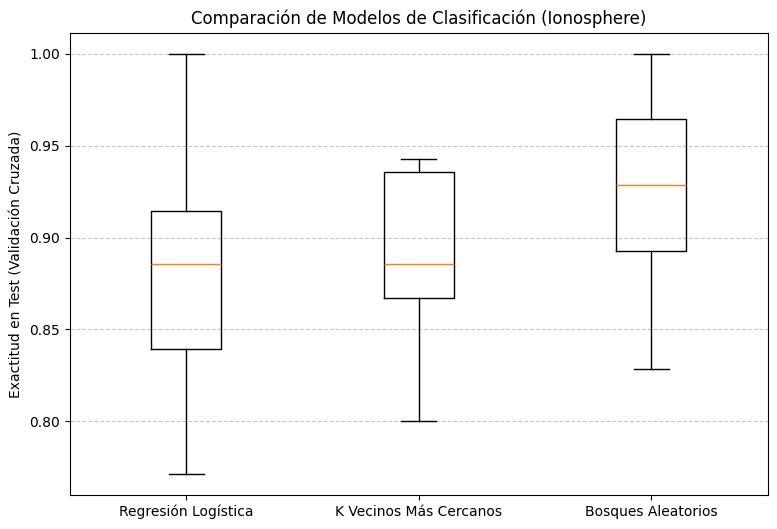

In [54]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score

# Carga y preprocesamiento del dataset
df_iono = pd.read_csv('data/ionosphere.csv', header=None)
X = df_iono.iloc[:, :-1].values
y = LabelEncoder().fit_transform(df_iono.iloc[:, -1].values)

# Definición de los modelos y sus hiperparámetros a explorar
modelos = {
    'Regresión Logística': GridSearchCV(
        estimator=make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
        param_grid={'logisticregression__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]},
        cv=5
    ),
    'K Vecinos Más Cercanos': GridSearchCV(
        estimator=make_pipeline(StandardScaler(), KNeighborsClassifier()),
        param_grid={'kneighborsclassifier__n_neighbors': [2, 4, 10, 20, 50]},
        cv=5
    ),
    'Bosques Aleatorios': GridSearchCV(
        estimator=RandomForestClassifier(random_state=1),
        param_grid={'n_estimators': [10, 50, 100, 200, 400]},
        cv=5
    )
}

resultados_cv = []
nombres_modelos = []

# Evaluación robusta de cada modelo usando validación cruzada
for nombre, modelo in modelos.items():
    # 10 pliegues para obtener una buena distribución de la exactitud
    scores = cross_val_score(modelo, X, y, cv=10, scoring='accuracy', n_jobs=-1)
    resultados_cv.append(scores)
    nombres_modelos.append(nombre)

# Dibujo del diagrama de caja
plt.figure(figsize=(9, 6))
plt.boxplot(resultados_cv, labels=nombres_modelos)
plt.title('Comparación de Modelos de Clasificación (Ionosphere)')
plt.ylabel('Exactitud en Test (Validación Cruzada)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Elección del modelo:** A la vista del diagrama de caja, el mejor modelo para este problema es el de **Bosques Aleatorios**. Como se observa en la gráfica, es el método que logra el rendimiento global superior: su mediana (línea naranja) alcanza una exactitud aproximada de 0.93, desmarcándose claramente de la Regresión Logística y KNN (cuyas medianas rondan apenas el 0.88). Además, aunque presenta cierta varianza en su límite inferior, el primer cuartil (la base de su caja) está situado por encima de las medianas de los otros dos modelos. Esto garantiza que en la inmensa mayoría de las particiones de la validación cruzada, el Bosque Aleatorio ofrece una exactitud mucho más alta que sus competidores.

b) Estudie el rendimiento de dos de los hiperparámetros del modelo determinado en el apartado anterior, use el hiperparámetro especificado en el apartado anterior y otro que considere oportuno. Indique cuál es la mejor configuración y cuál la peor. Ilustre y justifique sus razonamientos utilizando la gráfica o diagrama que crea adecuada.

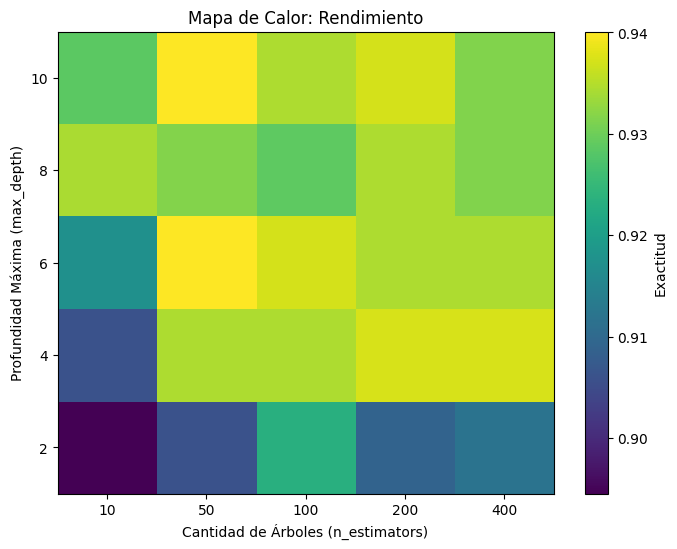

Mejor configuración: {'max_depth': 6, 'n_estimators': 50}


In [55]:
# Definir hiperparámetros
rango_estimadores = [10, 50, 100, 200, 400]
rango_profundidad = [2, 4, 6, 8, 10]

rejilla_rf = {
    'n_estimators': rango_estimadores,
    'max_depth': rango_profundidad
}

# Búsqueda en rejilla
busq_rejilla = GridSearchCV(estimator=RandomForestClassifier(random_state=1), 
                            param_grid=rejilla_rf, cv=10, scoring='accuracy', n_jobs=-1)
busq_rejilla.fit(X, y)

# Matriz pivotada para el mapa de calor
resultados = pd.DataFrame(busq_rejilla.cv_results_)
matriz_rendimientos = resultados.pivot(
    index="param_max_depth", 
    columns="param_n_estimators", 
    values="mean_test_score"
)

# Mapa de calor
plt.figure(figsize=(8, 6))
plt.imshow(matriz_rendimientos, cmap='viridis', aspect='auto', origin='lower')
plt.xticks(ticks=np.arange(len(rango_estimadores)), labels=rango_estimadores)
plt.yticks(ticks=np.arange(len(rango_profundidad)), labels=rango_profundidad)
plt.xlabel("Cantidad de Árboles (n_estimators)")
plt.ylabel("Profundidad Máxima (max_depth)")
plt.title("Mapa de Calor: Rendimiento")
plt.colorbar(label='Exactitud')
plt.show()

print(f"Mejor configuración: {busq_rejilla.best_params_}")

* **Peor configuración:** Como se observa en el mapa de calor, la peor configuración se encuentra en la esquina inferior izquierda. Esta corresponde a utilizar un modelo con muy pocos árboles (`n_estimators` = 10) y una profundidad muy limitada (`max_depth` = 2). El resultado es la exactitud más baja de la cuadrícula (por debajo de 0.90), lo que refleja un claro **subajuste** (*underfitting*): el modelo es demasiado simple para capturar la complejidad de los datos.
* **Mejor configuración:** El rendimiento óptimo se localiza en las celdas de color amarillo más brillante (alcanzando niveles cercanos a 0.94 de exactitud). Visualmente destaca la columna de 50 estimadores. Tal y como confirmó la salida por consola, la combinación ideal se logra con **50 árboles (`n_estimators` = 50)** y una **profundidad máxima de 6 (`max_depth` = 6)**. A partir de esa cantidad de árboles (hacia la derecha, con 100, 200 o 400), el rendimiento no solo no mejora, sino que la gráfica se vuelve más verdosa, indicando que añadir más complejidad no aporta beneficios y el modelo empieza a perder capacidad de generalización.

3) (1.5 ptos) Dibuje la curva ROC del peor método del primer apartado del ejercicio anterior usando su mejor configuración. Comente los resultados.

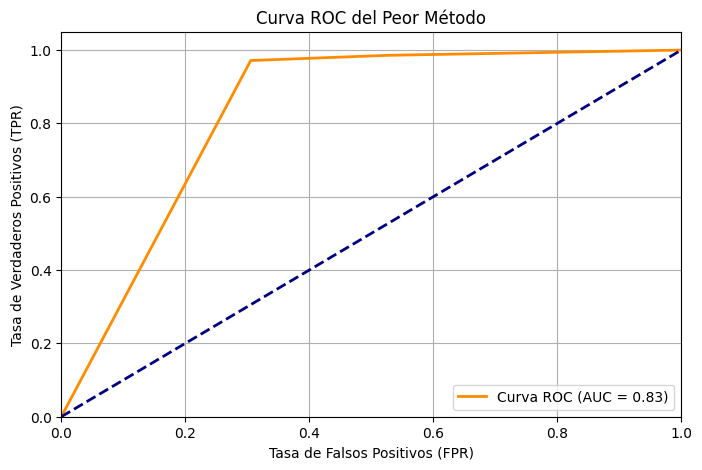

In [56]:
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split

# División de datos (usando X e y de los ejercicios anteriores)
X_ent, X_test, y_ent, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

# KNN fue el peor modelo, muy igualado con regresión logística, y k=2 su mejor configuración
peor_modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=2))
peor_modelo.fit(X_ent, y_ent)

# Probabilidades de pertenecer a la clase positiva
y_probs = peor_modelo.predict_proba(X_test)[:, 1]

# Cálculo de la curva ROC
fpr, tpr, umbrales = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

# Gráfica de la Curva ROC
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC del Peor Método')
plt.legend(loc="lower right")
plt.grid()
plt.show()

a) ¿Es capaz de lograr un resultado perfecto en términos de TPR? ¿Qué significaría esa situación? En caso de que lo consiga, ¿qué efectos produce respecto de la detección de muestras de la clase positiva y negativa?

* **¿Es capaz de lograr un resultado perfecto en términos de TPR?** 
Sí, observando la gráfica vemos que la curva naranja llega a alcanzar el valor $TPR = 1.0$ (el techo de la gráfica).
* **¿Qué significaría y qué efectos produce?**
Como se ve claramente en la imagen, la curva solo toca $TPR = 1.0$ cuando llega al extremo derecho, es decir, cuando $FPR = 1.0$. Esto significa que para detectar todos los positivos (100% de sensibilidad), el modelo se ve obligado a bajar su umbral al mínimo y clasificar **todas** las muestras del dataset como positivas. El efecto es devastador para la clase negativa: el modelo se equivoca en todos los casos negativos, generando un 100% de falsas alarmas.

b) ¿Es capaz de lograr un resultado perfecto en términos de FPR? ¿Qué significaría esa situación? En caso de que lo consiga, ¿qué efectos produce respecto de la detección de muestras de la clase positiva y negativa?

* **¿Es capaz de lograr un resultado perfecto en términos de FPR?**
Sí, la gráfica comienza en el valor $FPR = 0.0$ (el extremo izquierdo del eje X), lo que significa que es capaz de no emitir ninguna falsa alarma.
* **¿Qué significaría y qué efectos produce?**
Si miramos el punto exacto donde $FPR = 0.0$, vemos que se corresponde con el origen de coordenadas ($TPR = 0.0$). Esto significa que la única forma que tiene este modelo de no equivocarse nunca con los falsos positivos es subiendo el umbral al máximo y clasificando **todas** las muestras como negativas. El efecto es que la detección de la clase positiva se vuelve completamente nula (no detecta ni un solo caso real).

c) Imagine que para usted es prioritario detectar las muestras cuya clase deseada es la 1 (positiva), ¿cree que este modelo podría llegar a realizar esta tarea con un alto grado de confianza? Razone su respuesta.

* **Prioridad de detección de la clase positiva (1) con alto grado de confianza:**
**No**, este modelo no podría realizar esta tarea con un alto grado de confianza. 
Si analizamos visualmente la curva, vemos que tiene un "codo" muy marcado. Para lograr capturar la inmensa mayoría de las muestras positivas (por ejemplo, alcanzar un $TPR$ cercano a $0.98$ en el punto de inflexión), la gráfica nos muestra que estamos obligados a asumir un $FPR$ aproximado de $0.30$. 
Es decir, aunque lograríamos detectar casi todos los positivos, el coste a pagar es altísimo: un **30% de tasa de falsas alarmas**. En un entorno real, un sistema que levanta una alerta falsa el 30% de las veces en las que evalúa un caso negativo genera una gran desconfianza en el usuario.

4) (1.5 ptos) Considere el conjunto de muestras zoo.csv disponible en el Campus Virtual y realice las siguientes tareas:

a) Preprocese el conjunto de muestras y divida en un 80% para entrenamiento y un 20% para test. Pista: use el método drop(['columna'], axis=1) para eliminar columnas.

In [57]:
from sklearn.model_selection import train_test_split

df_zoo = pd.read_csv('data/zoo.csv')

# Uso del método drop para eliminar la primera columna como indica la pista
df_zoo = df_zoo.drop(df_zoo.columns[0], axis=1)

# Separación de características (X) y objetivo (y)
X_zoo = df_zoo.iloc[:, :-1].values
y_zoo = df_zoo.iloc[:, -1].values

# División 80% / 20%
X_ent_z, X_test_z, y_ent_z, y_test_z = train_test_split(
    X_zoo, y_zoo, test_size=0.20, random_state=42
)

b) Calcule la cantidad de muestras de cada clase.

In [58]:
print("Cantidad de muestras de cada clase (Original):")
print(pd.Series(y_zoo).value_counts().sort_index())

Cantidad de muestras de cada clase (Original):
1    40
2    20
3     5
4    13
5     4
6     8
7    10
Name: count, dtype: int64


c) Aplique a las muestras un modelo basado en árboles de decisión con profundidad máxima de 4. Calcule la puntuación F1 con un enfoque macro y con un enfoque micro. Pista: tenga en cuenta que para clases deseadas no binarias, en la función f1_score para medidas micro debe usar el argumento average='micro'

In [59]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score
arbol = DecisionTreeClassifier(max_depth=4, random_state=42)
arbol.fit(X_ent_z, y_ent_z)

# Predicciones
y_pred_z = arbol.predict(X_test_z)

# F1 con enfoques macro y micro
f1_macro = f1_score(y_test_z, y_pred_z, average='macro')
f1_micro = f1_score(y_test_z, y_pred_z, average='micro')

print(f"F1 Macro: {f1_macro:.4f}")
print(f"F1 Micro: {f1_micro:.4f}")

F1 Macro: 0.7222
F1 Micro: 0.8000


d) En el apartado anterior, ¿en cuál medida de rendimiento están sobrerrepresentadas las muestras de clases menos numerosas?, ¿por qué existe diferencia de rendimiento entre una medida y la otra? ¿qué significa que una sea mejor que la otra? Razone sus respuestas.

Están sobrerrepresentadas en la medida **F1 Macro**. El enfoque "macro" calcula la métrica para cada clase de forma independiente y luego hace la media aritmética sin importar el tamaño de la clase. Por tanto, la clase 5 (con solo 4 muestras) tiene exactamente el mismo peso en el resultado final que la clase 1 (con 40 muestras).

El F1 Micro cuenta los aciertos y errores de forma global. Al hacer esto, las clases mayoritarias dominan el cálculo. La diferencia ocurre porque nuestro modelo está acertando mucho en las clases con más muestras (lo que eleva el F1 Micro a 0.80), pero está fallando al intentar clasificar las clases minoritarias (lo que arrastra hacia abajo el promedio del F1 Macro a 0.72).

Ninguna es universalmente "mejor", ya que miden cosas distintas según el objetivo. Sin embargo, en datasets altamente desbalanceados como este, un F1 Macro bajo nos advierte de un problema real: el modelo está ignorando a las clases minoritarias. Si el objetivo es que el modelo sea justo y clasifique bien a todas las especies de animales por igual (independientemente de si hay muchos o pocos en el dataset), el F1 Macro es una métrica mucho más honesta y reveladora.

e) Realice un sobremuestreo para que haya el mismo número de muestras de cada clase. Muestre por pantalla la cantidad de muestras de cada clase en este nuevo conjunto de muestras.

In [60]:
# Importación nueva para sobremuestreo (requiere instalar imbalanced-learn)
from imblearn.over_sampling import RandomOverSampler 

# e) Sobremuestreo para igualar las clases
ros = RandomOverSampler(random_state=42)
X_res, y_res = ros.fit_resample(X_zoo, y_zoo)

print("Cantidad de muestras de cada clase (Tras sobremuestreo):")
print(pd.Series(y_res).value_counts().sort_index())

Cantidad de muestras de cada clase (Tras sobremuestreo):
1    40
2    40
3    40
4    40
5    40
6    40
7    40
Name: count, dtype: int64


### EJERCICIO AVANZADO
5) (2 ptos) Cargue el conjunto de datos Breast Cancer que viene incorporado en sklearn mediante el siguiente código:

```python
from sklearn.datasets import load_breast_cancer

data_breast_cancer = load_breast_cancer()
X = data_breast_cancer['data']
y = data_breast_cancer['target']
```
Haga una división en conjuntos de entrenamiento (70%) y test (30%), que usará en todo el ejercicio.

a) Entrene diferentes árboles de decisión. Pruebe con 1000 configuraciones de hiperparámetros elegidas uniformemente al azar de la siguiente manera: valores del mínimo de muestras para dividir un nodo (min_samples_split) desde 0 hasta 1, valores del mínimo de muestras para un nodo hoja (min_samples_leaf) desde 0 hasta 1, y valores del máximo de rasgos (max_features) desde 0 hasta 1. No debería tardar más de 10 segundos en hacer los 1000 entrenamientos. Mida la exactitud (accuracy) para los conjuntos de entrenamiento y test. Una vez hechas todas estas pruebas, genere dos gráficos tridimensionales (uno para los resultados en entrenamiento y otro para los resultados en test) en los que se puedan visualizar los resultados obtenidos. Los tres ejes coordenados deben corresponder a min_samples_split, min_samples_leaf y max_features. El color debe indicar el valor de la exactitud para el conjunto considerado (entrenamiento o test).

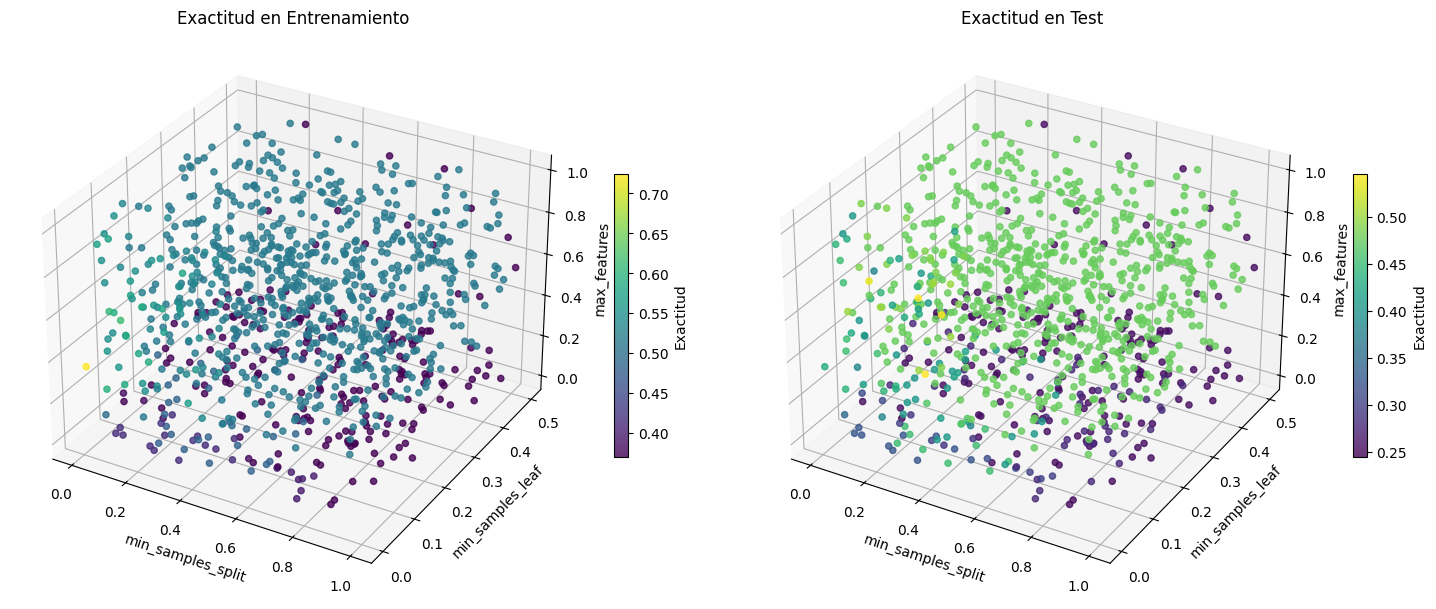

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder

# 1. Carga del CSV problemático
df_bc = pd.read_csv('data/breast-cancer.csv', header=None)

# 2. Separar la clase deseada (columna 1) de los rasgos (columna 2 en adelante)
X_texto = df_bc.loc[:, 2:]
y_texto = df_bc.loc[:, 1]

# 3. ¡LA SOLUCIÓN AL ERROR! Convertir todos los textos (ej. 'ge40') a números (0 y 1)
X = pd.get_dummies(X_texto, drop_first=True).values

# 4. Codificar la clase objetivo a valores numéricos
y = LabelEncoder().fit_transform(y_texto)

# 5. División en 70% entrenamiento y 30% test
X_ent, X_test, y_ent, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

# 6. Búsqueda aleatoria (1000 iteraciones)
resultados_entrenamiento = []
resultados_test = []

np.random.seed(42) # Para obtener siempre el mismo resultado aleatorio

for _ in range(1000):
    # Generar hiperparámetros aleatorios (min_samples_leaf no debe superar 0.5)
    mss = np.random.uniform(0.001, 1.0) 
    msl = np.random.uniform(0.001, 0.5) 
    mf = np.random.uniform(0.001, 1.0)  
    
    # Entrenar modelo
    arbol = DecisionTreeClassifier(
        min_samples_split=mss, 
        min_samples_leaf=msl, 
        max_features=mf,
        random_state=42
    )
    arbol.fit(X_ent, y_ent)
    
    # Guardar resultados
    resultados_entrenamiento.append([mss, msl, mf, arbol.score(X_ent, y_ent)])
    resultados_test.append([mss, msl, mf, arbol.score(X_test, y_test)])

df_train = pd.DataFrame(resultados_entrenamiento, columns=['mss', 'msl', 'mf', 'Exactitud'])
df_test = pd.DataFrame(resultados_test, columns=['mss', 'msl', 'mf', 'Exactitud'])

# 7. Generación de Gráficos 3D
fig = plt.figure(figsize=(15, 6))

# Gráfico 3D Entrenamiento
ax1 = fig.add_subplot(121, projection='3d')
sc1 = ax1.scatter(df_train['mss'], df_train['msl'], df_train['mf'], 
                  c=df_train['Exactitud'], cmap='viridis', s=20, alpha=0.8)
ax1.set_xlabel('min_samples_split')
ax1.set_ylabel('min_samples_leaf')
ax1.set_zlabel('max_features')
ax1.set_title('Exactitud en Entrenamiento')
fig.colorbar(sc1, ax=ax1, shrink=0.5, label='Exactitud')

# Gráfico 3D Test
ax2 = fig.add_subplot(122, projection='3d')
sc2 = ax2.scatter(df_test['mss'], df_test['msl'], df_test['mf'], 
                  c=df_test['Exactitud'], cmap='viridis', s=20, alpha=0.8)
ax2.set_xlabel('min_samples_split')
ax2.set_ylabel('min_samples_leaf')
ax2.set_zlabel('max_features')
ax2.set_title('Exactitud en Test')
fig.colorbar(sc2, ax=ax2, shrink=0.5, label='Exactitud')

plt.tight_layout()
plt.show()

b) ¿Se aprecia que el rendimiento del clasificador es sensible a los valores de min_samples_split, min_samples_leaf y max_features?

Sensibilidad del clasificador: Sí, es muy sensible. En la gráfica 3D se observan cambios bruscos de color (de cálidos a fríos) dependiendo de las coordenadas, lo que demuestra que elegir mal estos hiperparámetros desploma el rendimiento.

c) ¿Hay algún hiperparámetro que influya más en el rendimiento?

Hiperparámetro con más influencia: El min_samples_leaf. Si este parámetro toma valores cercanos a 0.5, se fuerza un subajuste extremo (el árbol no puede dividirse porque exige que el 50% de los datos vayan a cada rama). Esto hunde la exactitud independientemente de lo que valgan los otros dos parámetros.

### EJERCICIO EXPERTO
6) (2 ptos) Cargue el conjunto de datos Breast Cancer que viene incorporado en sklearn. Haz una división en conjuntos de entrenamiento (70%) y test (30%), que usará en todo el ejercicio.

a) Entrene diferentes máquinas de vectores soporte, usando el núcleo de función de base radial (Radial Basis Function, RBF). Pruebe con valores igualmente espaciados del parámetro de regularización C desde 0.01 hasta 5, y con valores igualmente espaciados del coeficiente del núcleo (gamma) desde 0.0001 hasta 0.01. Debe probar al menos 50 valores para C y 50 valores para gamma. Tenga en cuenta que debe probar las distintas combinaciones de valores de C y gamma, es decir, debe hacer al menos 50*50=2500 entrenamientos. No debería tardar más de 2 o 3 minutos en hacer los 2500 entrenamientos. Mida la exactitud (accuracy) para los conjuntos de entrenamiento y test. Una vez hechas todas estas pruebas, genere dos mapas de calor (conocidos como matrices de colores en las prácticas guiadas), uno para los resultados en entrenamiento y otro para los resultados en test, en los que se puedan visualizar los resultados obtenidos. El eje horizontal será el valor de gamma, y el eje vertical el valor de C. Recuerde que el color debe indicar el valor de la exactitud para el conjunto considerado (entrenamiento o test).

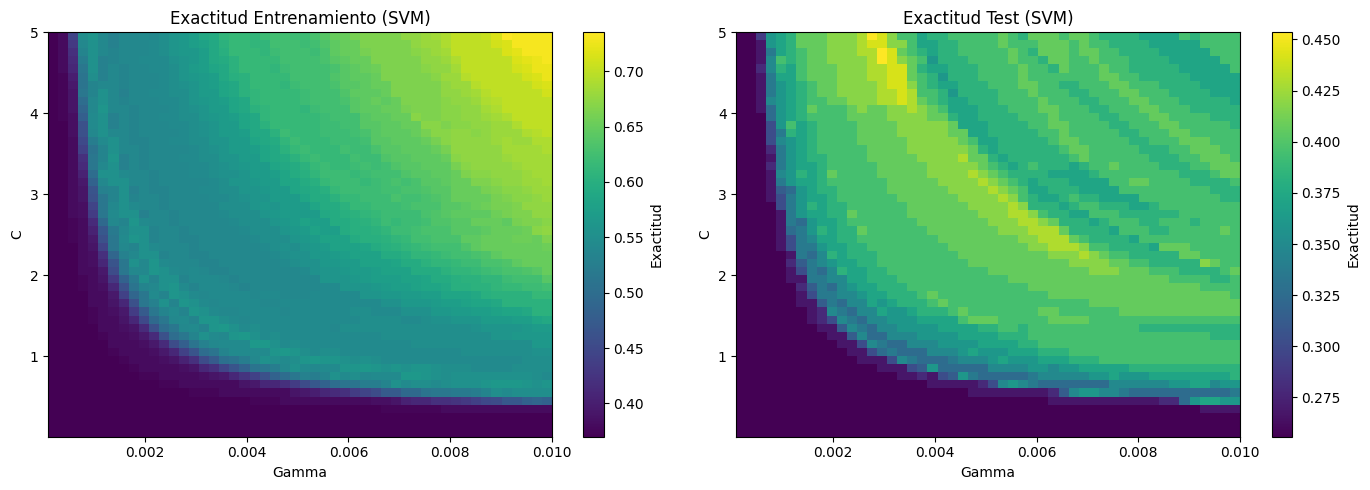

In [62]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

df_bc = pd.read_csv('data/breast-cancer.csv', header=None)

# Separar rasgos y clase (asumiendo clase en col 1 y rasgos desde col 2)
X_texto = df_bc.loc[:, 2:]
y_texto = df_bc.loc[:, 1]

# Convertir todo el texto a columnas numéricas de 0s y 1s
X_bc = pd.get_dummies(X_texto, drop_first=True).values
y_bc = LabelEncoder().fit_transform(y_texto)

# División en 70% entrenamiento y 30% test
X_ent, X_test, y_ent, y_test = train_test_split(
    X_bc, y_bc, test_size=0.30, random_state=42
)

scaler = StandardScaler()
X_ent_std = scaler.fit_transform(X_ent)
X_test_std = scaler.transform(X_test)

# 2500 entrenamientos (50x50)
rango_c = np.linspace(0.01, 5, 50)
rango_gamma = np.linspace(0.0001, 0.01, 50)

acc_train = np.zeros((50, 50))
acc_test = np.zeros((50, 50))

# Bucle de evaluación
for i, c in enumerate(rango_c):
    for j, g in enumerate(rango_gamma):
        svm = SVC(kernel='rbf', C=c, gamma=g)
        svm.fit(X_ent_std, y_ent)
        
        acc_train[i, j] = svm.score(X_ent_std, y_ent)
        acc_test[i, j] = svm.score(X_test_std, y_test)

# Mapas de Calor
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

cax1 = ax[0].imshow(acc_train, aspect='auto', origin='lower', cmap='viridis',
                    extent=[rango_gamma.min(), rango_gamma.max(), rango_c.min(), rango_c.max()])
ax[0].set_title('Exactitud Entrenamiento (SVM)')
ax[0].set_xlabel('Gamma')
ax[0].set_ylabel('C')
fig.colorbar(cax1, ax=ax[0], label='Exactitud')

cax2 = ax[1].imshow(acc_test, aspect='auto', origin='lower', cmap='viridis',
                    extent=[rango_gamma.min(), rango_gamma.max(), rango_c.min(), rango_c.max()])
ax[1].set_title('Exactitud Test (SVM)')
ax[1].set_xlabel('Gamma')
ax[1].set_ylabel('C')
fig.colorbar(cax2, ax=ax[1], label='Exactitud')

plt.tight_layout()
plt.show()

b) ¿Se aprecia que el rendimiento del clasificador es sensible a los valores de C y gamma?

**Sensibilidad del clasificador:** 
Sí, se aprecia claramente que el modelo SVM con kernel RBF es extremadamente sensible a la combinación de los hiperparámetros $C$ y $\gamma$. Observando los mapas generales del apartado "a", vemos una inmensa región de color morado muy oscuro en la parte inferior e izquierda (exactitud muy baja). Esto indica que si $C$ (fuerza de regularización) o $\gamma$ (radio de influencia de las muestras) toman valores demasiado bajos, el modelo es incapaz de ajustarse a los datos (fuerte subajuste). Conforme nos movemos en diagonal hacia la esquina superior derecha (aumentando ambos valores), el color cambia rápidamente hacia tonos verdes y amarillos, demostrando que la exactitud depende drásticamente de esta combinación precisa.

c) Repita el apartado a, pero en este caso variando los intervalos de valores de C y gamma. Debe identificar en la gráfica obtenida en el apartado “a” una región del mapa de calor de la exactitud en test que sea prometedora, es decir, que contenga valores altos de exactitud en test, y usar dicha región para elegir los intervalos de valores de C y gamma. Dicho de otra manera, se trata de ampliar (zoom) una región prometedora del mapa de calor obtenido en el apartado “a”.

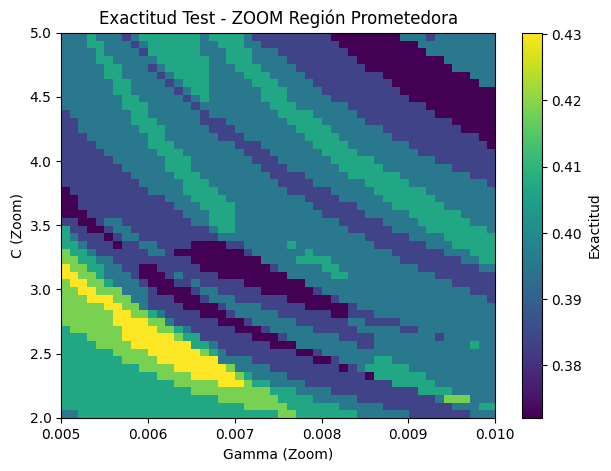

In [63]:
# Zoom en región de alta exactitud
zoom_c = np.linspace(2, 5, 50)
zoom_gamma = np.linspace(0.005, 0.01, 50)

acc_zoom_test = np.zeros((50, 50))

for i, c in enumerate(zoom_c):
    for j, g in enumerate(zoom_gamma):
        svm = SVC(kernel='rbf', C=c, gamma=g)
        svm.fit(X_ent_std, y_ent)
        acc_zoom_test[i, j] = svm.score(X_test_std, y_test)

# Mapa del Zoom
plt.figure(figsize=(7, 5))
plt.imshow(acc_zoom_test, aspect='auto', origin='lower', cmap='viridis',
           extent=[zoom_gamma.min(), zoom_gamma.max(), zoom_c.min(), zoom_c.max()])
plt.title('Exactitud Test - ZOOM Región Prometedora')
plt.xlabel('Gamma (Zoom)')
plt.ylabel('C (Zoom)')
plt.colorbar(label='Exactitud')
plt.show()

d) ¿Qué se observa en el segundo mapa de calor? ¿Hay estabilidad en los resultados?

**Observaciones y estabilidad en el mapa de calor ampliado (Zoom):**
Al hacer zoom en la región aparentemente prometedora, el segundo mapa de calor nos revela una estructura fragmentada. En lugar de ver un bloque uniforme y sólido de color amarillo (que indicaría un área óptima y segura), observamos un patrón muy marcado de "bandas" o "franjas" diagonales.

**No, no hay estabilidad.** El patrón de franjas demuestra que la exactitud es altamente volátil. Alternamos de forma abrupta entre pequeñas líneas de alta exactitud (color amarillo, en torno al 0.43) y bandas de baja exactitud (color morado oscuro, cayendo al 0.38). Esto significa que un cambio minúsculo en el valor de $\gamma$ o $C$ puede hacer que el modelo salte de un buen rendimiento a uno malo instantáneamente. Esta falta de suavidad en la región nos advierte de que el modelo es inestable y muy sensible a la mínima variación de los hiperparámetros.